In [2]:
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt #Plotting properties
import seaborn as sns #Plotting properties
from sklearn.model_selection import train_test_split #Data testing
from sklearn.linear_model import LogisticRegression #Prediction Model
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, r2_score, roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from sklearn.preprocessing import LabelEncoder #Variable encoding and decoding for XGBoost
import category_encoders as ce

import statsmodels.api as sm
from statsmodels.genmod.generalized_linear_model import GLM

ImportError: DLL load failed while importing _vector_sentinel: Una directiva de Control de aplicaciones bloqueó este archivo.

# 📺 Predicción de Churn Voluntario Premium

## Contexto y Variables Principales

Los datos utilizados en este cuaderno provienen del sector de telecomunicaciones y entretenimiento digital. Cada registro corresponde a un cliente con características asociadas a su comportamiento de uso y relación con la compañía. Se incluye información demográfica básica 🌍 (país, región), variables contractuales 📜 (método de pago, antigüedad del cliente, producto contratado), y consumo de servicios premium 🎬⚽ (movies, fútbol, adultos, otros).

Adicionalmente, se registran métricas de interacción con la compañía 📞 (llamadas entrantes y salientes), órdenes de trabajo gestionadas 🔧 y señales de insatisfacción como intenciones de baja o cancelaciones reincidentes ⚠️. También se consideran indicadores de valor futuro del cliente 💰 y segmentación CLTV, que ayudan a proyectar la relevancia de cada usuario dentro del negocio.

El objetivo principal es predecir la variable TARGET, que indica si un cliente realizará un churn voluntario premium (abandono del servicio de manera voluntaria). Este tipo de análisis resulta esencial para las empresas, ya que permite diseñar estrategias de retención más efectivas, identificar perfiles de riesgo y optimizar recursos destinados a la fidelización de clientes.

| Variables                   | Descripción                                      |
|-----------------------------|--------------------------------------------------|
| MES                         | Variable Año / Mes Corte                         |
| COD_PAIS                    | País                                             |
| CLASE                       | Variable Regional Speed Test                     |
| CUSTOMER_ID                 | ID                                               |
| MOP                         | Método de Pago                                   |
| AGRUP_BASICO                | Producto Clásico                                 |
| CANT_PREMIUM                | Cantidad Total Productos Premium Contratados     |
| CANT_MOVIES                 | Cantidad Premium Movies Contratados              |
| CANT_FUTBOL                  | Cantidad Premium Futbol Contratados              |
| CANT_ADULTOS                | Cantidad Premium Adultos Contratados             |
| CANT_OTRO_PREMIUM           | Cantidad Premium Otros Contratados               |
| CANT_FUTBOL_LOCAL           | Cantidad Premium Futbol Local Contratados        |
| WO                          | Numero Ordenes de Trabajo                        |
| TELEFONO_IN                 | Numero llamadas del cliente en el mes            |
| TELEFONO_OUT                | Numero llamadas al cliente en el mes             |
| INTENCIONES_BAJA            | Intenciones Cancelación                          |
| INTENCIONES_BAJA_REINCIDENTES | Intenciones Cancelación reincidentes           |
| RANGO_ANTIGUEDAD            | Rango Antigüedad Total Cliente                   |
| CFV                         | Valor Futuro del cliente                         |
| TECNOLOGIA                  | Tecnología                                       |
| ANTIGÜEDAD                  | Antigüedad Total Cliente                         |
| CLTV_NEW                    | Segmento CLTV                                    |
| TARGET                      | Variable Objetivo Churn Voluntario Premium       |


# Carga de datos

In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
df = pd.read_csv('BASE_MODELO_VOLUNTARIO.csv', sep=';')
df.head()

,MES,COD_PAIS,CLASE,CUSTOMER_ID,MOP,AGRUP_BASICO,CANT_PREMIUM,CANT_MOVIES,CANT_FUTBOL,CANT_ADULTOS,CANT_OTRO_PREMIUM,CANT_FUTBOL_LOCAL,WO,TELEFONO_IN,TELEFONO_OUT,INTENCIONES_BAJA,INTENCIONES_BAJA_REINCIDENTES,RANGO_ANTIGUEDAD,CLTV,TECNOLOGIA,ANTIGUEDAD,CLTV_NEW,TARGET
0,201811,EC,WHITE,1,Tarjeta de Credito,ORO,2,2,0,0,0,0,0,4,0,0,0,+24,7418.160956,NEXUS,43,3.High,0
1,201811,EC,GREY,4,Debito Bancario,ORO,1,1,0,0,0,0,0,0,0,0,0,+24,2003.364155,IRD,72,3.High,0
2,201810,EC,GREY,5,Tarjeta de Credito,ORO,1,1,0,0,0,0,0,0,0,0,0,+24,4077.205858,IRD HD DVR,108,3.High,0
3,201812,EC,GREY,6,Debito Bancario,BRONCE,1,1,0,0,0,0,0,0,0,0,0,+24,-425.743249,IRD HD,41,0.Negativo,1
4,201811,EC,WHITE,7,Tarjeta de Credito,PLATA,2,2,0,0,0,0,0,1,0,0,0,+24,3315.075786,IRD HD DVR,46,3.High,0


In [ ]:
df = df.set_index(['MES', 'COD_PAIS', 'CUSTOMER_ID'])
df.head()

CLASE                 MOP AGRUP_BASICO  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       1            WHITE  Tarjeta de Credito          ORO   
                4             GREY     Debito Bancario          ORO   
201810 EC       5             GREY  Tarjeta de Credito          ORO   
201812 EC       6             GREY     Debito Bancario       BRONCE   
201811 EC       7            WHITE  Tarjeta de Credito        PLATA   

                             CANT_PREMIUM  CANT_MOVIES  CANT_FUTBOL  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       1                       2            2            0   
                4                       1            1            0   
201810 EC       5                       1            1            0   
201812 EC       6                       1            1            0   
201811 EC       7                       2            2            0   

                             CANT_ADULTOS  CANT_OTRO_PREMIUM  \
MES    COD_PAIS CUSTOMER_ID                                    
201811 EC       1                       0                  0   
                4                       0                  0   
201810 EC       5                       0                  0   
201812 EC       6                       0                  0   
201811 EC       7                       0                  0   

                             CANT_FUTBOL_LOCAL  WO  TELEFONO_IN  TELEFONO_OUT  \
MES    COD_PAIS CUSTOMER_ID                                                     
201811 EC       1                            0   0            4             0   
                4                            0   0            0             0   
201810 EC       5                            0   0            0             0   
201812 EC       6                            0   0            0             0   
201811 EC       7                            0   0            1             0   

                             INTENCIONES_BAJA  INTENCIONES_BAJA_REINCIDENTES  \
MES    COD_PAIS CUSTOMER_ID                                                    
201811 EC       1                           0                              0   
                4                           0                              0   
201810 EC       5                           0                              0   
201812 EC       6                           0                              0   
201811 EC       7                           0                              0   

                            RANGO_ANTIGUEDAD         CLTV  TECNOLOGIA  \
MES    COD_PAIS CUSTOMER_ID                                             
201811 EC       1                        +24  7418.160956       NEXUS   
                4                        +24  2003.364155         IRD   
201810 EC       5                        +24  4077.205858  IRD HD DVR   
201812 EC       6                        +24  -425.743249      IRD HD   
201811 EC       7                        +24  3315.075786  IRD HD DVR   

                             ANTIGUEDAD    CLTV_NEW  TARGET  
MES    COD_PAIS CUSTOMER_ID                                  
201811 EC       1                    43      3.High       0  
                4                    72      3.High       0  
201810 EC       5                   108      3.High       0  
201812 EC       6                    41  0.Negativo       1  
201811 EC       7                    46      3.High       0

In [ ]:
df.describe(include='all')

,CLASE,MOP,AGRUP_BASICO,CANT_PREMIUM,CANT_MOVIES,CANT_FUTBOL,CANT_ADULTOS,CANT_OTRO_PREMIUM,CANT_FUTBOL_LOCAL,WO,TELEFONO_IN,TELEFONO_OUT,INTENCIONES_BAJA,INTENCIONES_BAJA_REINCIDENTES,RANGO_ANTIGUEDAD,CLTV,TECNOLOGIA,ANTIGUEDAD,CLTV_NEW,TARGET
count,43620,43620,43620,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620,43620.000000,43620,43620.000000,43620,43620.000000
unique,4,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,6,NaN,4,NaN
top,GREY,Tarjeta de Credito,ORO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,+24,NaN,IRD HD,NaN,3.High,NaN
freq,17930,30818,20722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38630,NaN,15994,NaN,28339,NaN
mean,NaN,NaN,NaN,1.474874,1.336520,0.016277,0.014397,0.107680,0.000275,0.047409,0.319922,0.508001,0.023453,0.014145,NaN,2709.609887,NaN,76.810706,NaN,0.086245
std,NaN,NaN,NaN,0.570475,0.620408,0.126902,0.128206,0.325633,0.016584,0.313243,0.938593,1.457894,0.151338,0.183095,NaN,4756.834299,NaN,49.335622,NaN,0.280728
min,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,-14533.487610,NaN,13.000000,NaN,0.000000
25%,NaN,NaN,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1012.496171,NaN,41.000000,NaN,0.000000
50%,NaN,NaN,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2245.889339,NaN,68.000000,NaN,0.000000
75%,NaN,NaN,NaN,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,3952.460616,NaN,101.000000,NaN,0.000000


In [ ]:
df_numericas = df.select_dtypes(include=[np.number]).columns
df_caracter = df.select_dtypes(include=['object']).columns

In [ ]:
df_numericas, df_caracter

(Index(['CANT_PREMIUM', 'CANT_MOVIES', 'CANT_FUTBOL', 'CANT_ADULTOS',
        'CANT_OTRO_PREMIUM', 'CANT_FUTBOL_LOCAL', 'WO', 'TELEFONO_IN',
        'TELEFONO_OUT', 'INTENCIONES_BAJA', 'INTENCIONES_BAJA_REINCIDENTES',
        'CLTV', 'ANTIGUEDAD', 'TARGET'],
       dtype='object'),
 Index(['CLASE', 'MOP', 'AGRUP_BASICO', 'RANGO_ANTIGUEDAD', 'TECNOLOGIA',
        'CLTV_NEW'],
       dtype='object'))

In [ ]:
df[df_numericas] = df[df_numericas].fillna(0)
df[df_caracter] = df[df_caracter].fillna("No info")

In [ ]:
df.describe(include='all')

,CLASE,MOP,AGRUP_BASICO,CANT_PREMIUM,CANT_MOVIES,CANT_FUTBOL,CANT_ADULTOS,CANT_OTRO_PREMIUM,CANT_FUTBOL_LOCAL,WO,TELEFONO_IN,TELEFONO_OUT,INTENCIONES_BAJA,INTENCIONES_BAJA_REINCIDENTES,RANGO_ANTIGUEDAD,CLTV,TECNOLOGIA,ANTIGUEDAD,CLTV_NEW,TARGET
count,43620,43620,43620,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620.000000,43620,43620.000000,43620,43620.000000,43620,43620.000000
unique,4,2,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,6,NaN,4,NaN
top,GREY,Tarjeta de Credito,ORO,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,+24,NaN,IRD HD,NaN,3.High,NaN
freq,17930,30818,20722,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,38630,NaN,15994,NaN,28339,NaN
mean,NaN,NaN,NaN,1.474874,1.336520,0.016277,0.014397,0.107680,0.000275,0.047409,0.319922,0.508001,0.023453,0.014145,NaN,2709.609887,NaN,76.810706,NaN,0.086245
std,NaN,NaN,NaN,0.570475,0.620408,0.126902,0.128206,0.325633,0.016584,0.313243,0.938593,1.457894,0.151338,0.183095,NaN,4756.834299,NaN,49.335622,NaN,0.280728
min,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,-14533.487610,NaN,13.000000,NaN,0.000000
25%,NaN,NaN,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1012.496171,NaN,41.000000,NaN,0.000000
50%,NaN,NaN,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2245.889339,NaN,68.000000,NaN,0.000000
75%,NaN,NaN,NaN,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,3952.460616,NaN,101.000000,NaN,0.000000


In [ ]:
df.isnull().sum()

CLASE                            0
MOP                              0
AGRUP_BASICO                     0
CANT_PREMIUM                     0
CANT_MOVIES                      0
CANT_FUTBOL                      0
CANT_ADULTOS                     0
CANT_OTRO_PREMIUM                0
CANT_FUTBOL_LOCAL                0
WO                               0
TELEFONO_IN                      0
TELEFONO_OUT                     0
INTENCIONES_BAJA                 0
INTENCIONES_BAJA_REINCIDENTES    0
RANGO_ANTIGUEDAD                 0
CLTV                             0
TECNOLOGIA                       0
ANTIGUEDAD                       0
CLTV_NEW                         0
TARGET                           0
dtype: int64

## ⚙️ Modelo de regresión logística

In [ ]:
df['TARGET'].value_counts(), df['TARGET'].value_counts(normalize=True)

(TARGET
 0    39858
 1     3762
 Name: count, dtype: int64,
 TARGET
 0    0.913755
 1    0.086245
 Name: proportion, dtype: float64)

## Pre-procesamiento

In [ ]:
encoder = ce.OneHotEncoder(cols=list(df_caracter), use_cat_names=True)
df_encoded = encoder.fit_transform(df)

df_encoded.head()

CLASE_WHITE  CLASE_GREY  CLASE_BLACK  \
MES    COD_PAIS CUSTOMER_ID                                         
201811 EC       1                      1           0            0   
                4                      0           1            0   
201810 EC       5                      0           1            0   
201812 EC       6                      0           1            0   
201811 EC       7                      1           0            0   

                             CLASE_Without Testers  MOP_Tarjeta de Credito  \
MES    COD_PAIS CUSTOMER_ID                                                  
201811 EC       1                                0                       1   
                4                                0                       0   
201810 EC       5                                0                       1   
201812 EC       6                                0                       0   
201811 EC       7                                0                       1   

                             MOP_Debito Bancario  AGRUP_BASICO_ORO  \
MES    COD_PAIS CUSTOMER_ID                                          
201811 EC       1                              0                 1   
                4                              1                 1   
201810 EC       5                              0                 1   
201812 EC       6                              1                 0   
201811 EC       7                              0                 0   

                             AGRUP_BASICO_BRONCE  AGRUP_BASICO_PLATA  \
MES    COD_PAIS CUSTOMER_ID                                            
201811 EC       1                              0                   0   
                4                              0                   0   
201810 EC       5                              0                   0   
201812 EC       6                              1                   0   
201811 EC       7                              0                   1   

                             CANT_PREMIUM  CANT_MOVIES  CANT_FUTBOL  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       1                       2            2            0   
                4                       1            1            0   
201810 EC       5                       1            1            0   
201812 EC       6                       1            1            0   
201811 EC       7                       2            2            0   

                             CANT_ADULTOS  CANT_OTRO_PREMIUM  \
MES    COD_PAIS CUSTOMER_ID                                    
201811 EC       1                       0                  0   
                4                       0                  0   
201810 EC       5                       0                  0   
201812 EC       6                       0                  0   
201811 EC       7                       0                  0   

                             CANT_FUTBOL_LOCAL  WO  TELEFONO_IN  TELEFONO_OUT  \
MES    COD_PAIS CUSTOMER_ID                                                     
201811 EC       1                            0   0            4             0   
                4                            0   0            0             0   
201810 EC       5                            0   0            0             0   
201812 EC       6                            0   0            0             0   
201811 EC       7                            0   0            1             0   

                             INTENCIONES_BAJA  INTENCIONES_BAJA_REINCIDENTES  \
MES    COD_PAIS CUSTOMER_ID                                                    
201811 EC       1                           0                              0   
                4                           0                              0   
201810 EC       5                           0                              0   
201812 EC       6                           0                              0   
201811 

In [ ]:
X = df_encoded.drop(columns=['TARGET'])
y = df_encoded['TARGET']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print('Observaciones en entrenamiento: {}'.format(len(X_train)))
print('Observaciones en Test: {}'.format(len(X_test)))

Observaciones en entrenamiento: 34896
Observaciones en Test: 8724


In [ ]:

logreg = LogisticRegression(max_iter=10000)
logreg.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [ ]:
# --- 2) Predecir ---
y_pred_train = logreg.predict(X_train)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_train, y_pred_train))
print("\nClassification report:\n", classification_report(y_train, y_pred_train))

Accuracy: 0.9288743695552499

Classification report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.96     31900
           1       0.91      0.19      0.32      2996

    accuracy                           0.93     34896
   macro avg       0.92      0.59      0.64     34896
weighted avg       0.93      0.93      0.91     34896



In [ ]:
confusion_matrix(y_train, y_pred_train)

array([[31840,    60],
       [ 2422,   574]])

In [ ]:
# --- 2) Predecir ---
y_pred = logreg.predict(X_test)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9264099037138928

Classification report:
               precision    recall  f1-score   support

           0       0.93      1.00      0.96      7958
           1       0.92      0.18      0.30       766

    accuracy                           0.93      8724
   macro avg       0.92      0.59      0.63      8724
weighted avg       0.93      0.93      0.90      8724



In [ ]:
confusion_matrix(y_test, y_pred)

array([[7946,   12],
       [ 630,  136]])

In [ ]:
y_proba = logreg.predict_proba(X_test)[:, 1]  # Probabilidades de la clase positiva

Umbral (Youden J): 0.0878
Umbral (Dist. a (0,1) mínima): 0.0672
Umbral (mejor F1 en PR): 0.1440


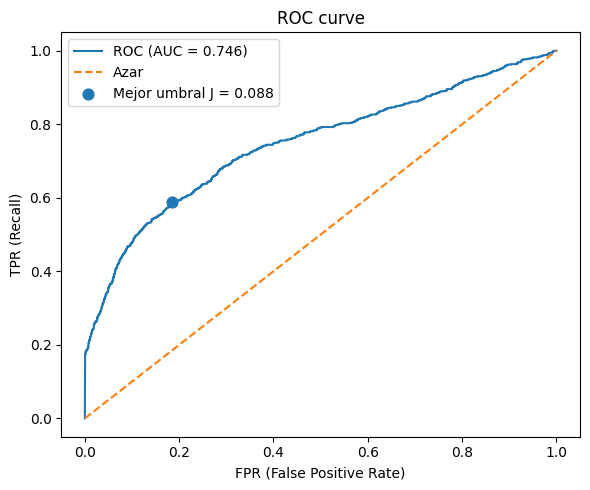

In [ ]:
# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)  # guarda thresholds
auc_roc = roc_auc_score(y_test, y_proba)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.1440
Precision=0.356  Recall=0.436  F1=0.392
Average Precision (AP): 0.403


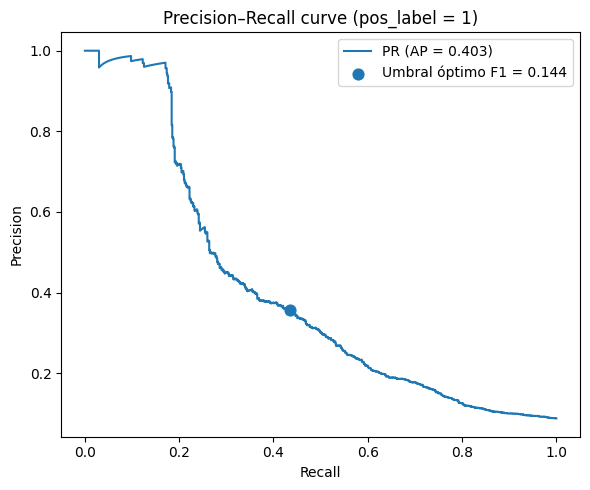

In [ ]:
pos_label = logreg.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = logreg.classes_[1]
neg_label = logreg.classes_[0]
pos_idx = list(logreg.classes_).index(pos_label)

y_proba = logreg.predict_proba(X_test)[:, pos_idx]

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.8812471343420449

Classification report (umbral óptimo):
               precision    recall  f1-score   support

           0       0.94      0.92      0.93      7958
           1       0.36      0.44      0.39       766

    accuracy                           0.88      8724
   macro avg       0.65      0.68      0.66      8724
weighted avg       0.89      0.88      0.89      8724



# ⚖️ Introducción al Problema del Desbalanceo de Clases


Los datos desbalanceados se refieren a conjuntos de datos donde la variable objetivo presenta una distribución desigual de observaciones, es decir, una de las clases tiene un número muy alto de observaciones, mientras que la otra tiene un número muy reducido de observaciones. ✅

En muchos problemas reales de clasificación, las categorías o clases no aparecen con la misma frecuencia.
Por ejemplo:

 - 🔎 Fraude financiero: el 99% de las transacciones son legítimas y solo el 1% son fraudulentas.

 - 🏥 Diagnóstico médico: la mayoría de los pacientes están sanos y un pequeño grupo presenta una enfermedad rara.

 - 📧 Spam en correos electrónicos: la mayor parte son correos normales y solo una fracción son spam.

Este fenómeno se conoce como desbalanceo de clases y genera un gran desafío para los modelos de machine learning, incluyendo la regresión logística.

## 🚨 ¿Por qué es un problema?

 - 📊 Distribución Sesgada de Clases

Un dataset desbalanceado ocurre cuando una clase (la minoritaria) está significativamente subrepresentada frente a la otra clase (la mayoritaria) en un problema de clasificación.
Esto puede sesgar el proceso de aprendizaje del modelo, ya que tenderá a priorizar la clase mayoritaria, generando un mal desempeño en la clase minoritaria.

 - ⚖️ Entrenamiento Sesgado del Modelo

Los modelos de machine learning buscan minimizar errores, normalmente medidos con métricas como la exactitud (accuracy).
En datasets desbalanceados, un modelo puede lograr alta exactitud simplemente prediciendo siempre la clase mayoritaria, ignorando por completo la clase minoritaria.
Como resultado, el modelo queda sesgado hacia la mayoría y no logra capturar los patrones de la minoría.

 - 🌐 Mala Generalización

El desbalanceo puede producir modelos que generalizan mal en datos nuevos, especialmente para la clase minoritaria.
Dado que el modelo no ha aprendido lo suficiente sobre ella (por su escasez en el entrenamiento), tendrá dificultades para hacer predicciones correctas en escenarios reales.

 - 💸 Errores Costosos

En muchas aplicaciones reales, clasificar mal la clase minoritaria puede ser más costoso o tener consecuencias más graves que clasificar mal la clase mayoritaria.
El desbalanceo agrava este problema porque el modelo tiende a equivocarse más con la minoría, lo que puede generar impactos negativos significativos.

 - 📉 Métricas de Evaluación Engañosas

Las métricas tradicionales como la exactitud (accuracy) pueden ser engañosas en datasets desbalanceados.
Por ejemplo, un modelo con alta exactitud puede tener un desempeño pésimo en la clase minoritaria (que suele ser la más importante).

# Soluciones para el desbalanceo

## ⚙️ Manejo del desbalanceo desde la instanciación del modelo

Regresión Logística con class_weight="balanced"

Ajusta automáticamente los pesos inversamente proporcionales a la frecuencia de cada clase.

In [ ]:
logreg = LogisticRegression(
    solver="lbfgs",          # "saga" si tu X es dispersa (TF-IDF)
    class_weight="balanced", # clave para el desbalanceo
    C=1.0,                   # regularización (ajústalo)
    max_iter=2000,
    n_jobs=-1
)


In [ ]:
logreg.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [ ]:
# --- 2) Predecir ---
y_pred = logreg.predict(X_test)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7847317744154058

Classification report:
               precision    recall  f1-score   support

           0       0.95      0.80      0.87      7958
           1       0.23      0.60      0.33       766

    accuracy                           0.78      8724
   macro avg       0.59      0.70      0.60      8724
weighted avg       0.89      0.78      0.82      8724



In [ ]:
confusion_matrix(y_test, y_pred)

array([[6389, 1569],
       [ 309,  457]])

In [ ]:
y_proba = logreg.predict_proba(X_test)[:, 1]  # Probabilidades de la clase positiva

Umbral (Youden J): 0.4490
Umbral (Dist. a (0,1) mínima): 0.4490
Umbral (mejor F1 en PR): 0.6460


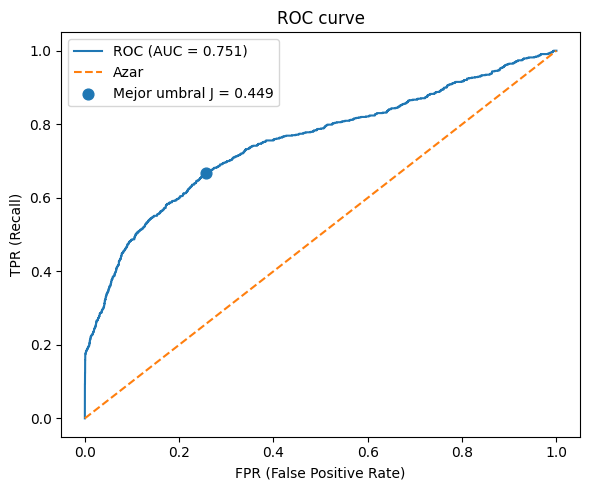

In [ ]:
# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)  # guarda thresholds
auc_roc = roc_auc_score(y_test, y_proba)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.6460
Precision=0.355  Recall=0.449  F1=0.397
Average Precision (AP): 0.402


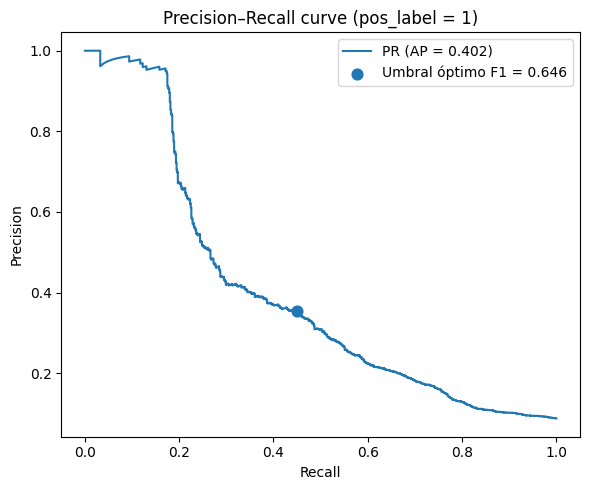

In [ ]:
pos_label = logreg.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = logreg.classes_[1]
neg_label = logreg.classes_[0]
pos_idx = list(logreg.classes_).index(pos_label)

y_proba = logreg.predict_proba(X_test)[:, pos_idx]

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.8801008711600183

Classification report (umbral óptimo):
               precision    recall  f1-score   support

           0       0.95      0.92      0.93      7958
           1       0.36      0.45      0.40       766

    accuracy                           0.88      8724
   macro avg       0.65      0.69      0.67      8724
weighted avg       0.89      0.88      0.89      8724




## 🔄 Re-muestreo (Oversampling y Undersampling)

Estas técnicas son utilizadas para manejar datos desbalanceados consiste en aumentar (oversampling) o reducir (undersampling) la clase minoritaria o mayoritaria.

 - Oversampling (sobremuestreo): cuando trabajamos con un dataset desbalanceado, podemos replicar instancias de la clase minoritaria (con reemplazo). Esta técnica busca equilibrar el dataset aumentando la representación de la clase menos frecuente.

![image-2.png](attachment:image-2.png)

 - Undersampling (submuestreo): de manera similar, podemos eliminar aleatoriamente registros de la clase mayoritaria hasta igualar el número de observaciones con la clase minoritaria.

![image.png](attachment:image.png)

Después de aplicar estas técnicas, obtenemos un conjunto de datos balanceado para ambas clases.
Cuando ambas clases tienen un número similar de registros en el dataset, se asume que el clasificador dará igual importancia a cada una.

In [ ]:
y_train

MES     COD_PAIS  CUSTOMER_ID
201811  EC        67691          0
201810  EC        26945          0
201811  EC        91373          0
                  20617          0
                  90421          0
                                ..
201812  EC        69842          0
201810  EC        48708          0
201811  EC        97703          1
201812  EC        99885          1
201811  EC        6238           0
Name: TARGET, Length: 34896, dtype: int64

In [ ]:
from sklearn.utils import resample
#create two different dataframe of majority and minority class 
X_t = pd.concat([X_train, y_train], axis=1)
X_t.head()

CLASE_WHITE  CLASE_GREY  CLASE_BLACK  \
MES    COD_PAIS CUSTOMER_ID                                         
201811 EC       67691                  0           1            0   
201810 EC       26945                  0           1            0   
201811 EC       91373                  0           0            1   
                20617                  1           0            0   
                90421                  1           0            0   

                             CLASE_Without Testers  MOP_Tarjeta de Credito  \
MES    COD_PAIS CUSTOMER_ID                                                  
201811 EC       67691                            0                       1   
201810 EC       26945                            0                       1   
201811 EC       91373                            0                       1   
                20617                            0                       1   
                90421                            0                       1   

                             MOP_Debito Bancario  AGRUP_BASICO_ORO  \
MES    COD_PAIS CUSTOMER_ID                                          
201811 EC       67691                          0                 0   
201810 EC       26945                          0                 0   
201811 EC       91373                          0                 0   
                20617                          0                 0   
                90421                          0                 1   

                             AGRUP_BASICO_BRONCE  AGRUP_BASICO_PLATA  \
MES    COD_PAIS CUSTOMER_ID                                            
201811 EC       67691                          1                   0   
201810 EC       26945                          0                   1   
201811 EC       91373                          0                   1   
                20617                          0                   1   
                90421                          0                   0   

                             CANT_PREMIUM  CANT_MOVIES  CANT_FUTBOL  \
MES    COD_PAIS CUSTOMER_ID                                           
201811 EC       67691                   2            1            0   
201810 EC       26945                   1            1            0   
201811 EC       91373                   1            1            0   
                20617                   1            1            0   
                90421                   2            2            0   

                             CANT_ADULTOS  CANT_OTRO_PREMIUM  \
MES    COD_PAIS CUSTOMER_ID                                    
201811 EC       67691                   0                  1   
201810 EC       26945                   0                  0   
201811 EC       91373                   0                  0   
                20617                   0                  0   
                90421                   0                  0   

                             CANT_FUTBOL_LOCAL  WO  TELEFONO_IN  TELEFONO_OUT  \
MES    COD_PAIS CUSTOMER_ID                                                     
201811 EC       67691                        0   0            0             0   
201810 EC       26945                        0   1            1             1   
201811 EC       91373                        0   0            0             5   
                20617                        0   0            0             0   
                90421                        0   0            0             0   

                             INTENCIONES_BAJA  INTENCIONES_BAJA_REINCIDENTES  \
MES    COD_PAIS CUSTOMER_ID                                                    
201811 EC       67691                       0                              0   
201810 EC       26945                       0                              0   
201811 EC       91373                       0                              0   
                20617                       0                              0   
       

In [ ]:

X_majority = X_t[(X_t['TARGET']==0)] 
X_minority = X_t[(X_t['TARGET']==1)] 
X_majority.shape, X_minority.shape

((31900, 35), (2996, 35))

In [ ]:
X_minority_upsampled = resample(X_minority, 
                                 replace=True,    # sample with replacement
                                 n_samples= X_majority.shape[0], # to match majority class
                                 random_state=42)  # reproducible results
# Combine majority class with upsampled minority class
X_train_upsampled = pd.concat([X_minority_upsampled, X_majority])
X_train_upsampled['TARGET'].value_counts()

TARGET
1    31900
0    31900
Name: count, dtype: int64

In [ ]:
X_train_up = X_train_upsampled.drop(columns=['TARGET'])
y_train_up = X_train_upsampled['TARGET']

In [ ]:

logreg = LogisticRegression(max_iter=10000)
logreg.fit(X_train_up, y_train_up)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [ ]:
# --- 2) Predecir ---
y_pred = logreg.predict(X_test)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.7877120586886749

Classification report:
               precision    recall  f1-score   support

           0       0.95      0.81      0.87      7958
           1       0.23      0.60      0.33       766

    accuracy                           0.79      8724
   macro avg       0.59      0.70      0.60      8724
weighted avg       0.89      0.79      0.83      8724



In [ ]:
confusion_matrix(y_test, y_pred)

array([[6415, 1543],
       [ 309,  457]])

In [ ]:
y_proba = logreg.predict_proba(X_test)[:, 1]  # Probabilidades de la clase positiva

Umbral (Youden J): 0.4528
Umbral (Dist. a (0,1) mínima): 0.4528
Umbral (mejor F1 en PR): 0.6499


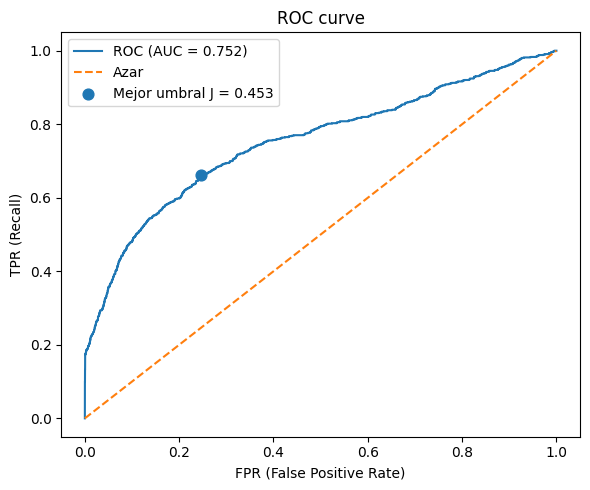

In [ ]:
# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)  # guarda thresholds
auc_roc = roc_auc_score(y_test, y_proba)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.6499
Precision=0.355  Recall=0.443  F1=0.394
Average Precision (AP): 0.403


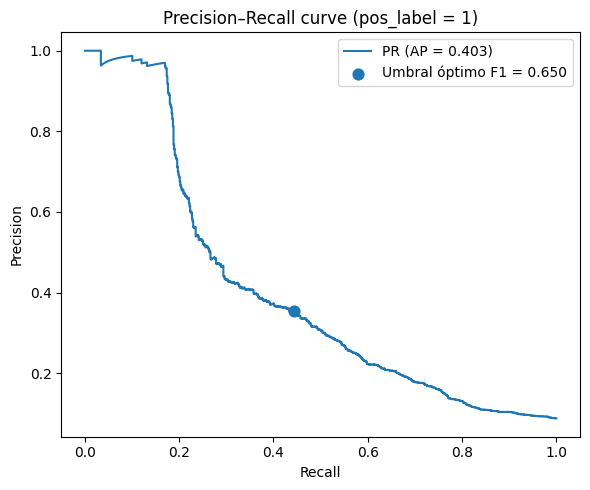

In [ ]:
pos_label = logreg.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = logreg.classes_[1]
neg_label = logreg.classes_[0]
pos_idx = list(logreg.classes_).index(pos_label)

y_proba = logreg.predict_proba(X_test)[:, pos_idx]

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.880559376432829

Classification report (umbral óptimo):
               precision    recall  f1-score   support

           0       0.95      0.92      0.93      7958
           1       0.36      0.44      0.39       766

    accuracy                           0.88      8724
   macro avg       0.65      0.68      0.66      8724
weighted avg       0.89      0.88      0.89      8724



## 🧬 SMOTE

La siguiente técnica para manejar datos desbalanceados es el Synthetic Minority Oversampling Technique (SMOTE), que es otra forma de sobremuestrear la clase minoritaria.

A diferencia de simplemente duplicar registros de la clase minoritaria —lo cual no agrega nueva información al modelo—, SMOTE sintetiza nuevas instancias a partir de los datos existentes.

Explicado en palabras simples: SMOTE observa las instancias de la clase minoritaria y utiliza el algoritmo de k vecinos más cercanos (k-NN) para seleccionar un vecino aleatorio. Luego, genera una instancia sintética de manera aleatoria en el espacio de características.

A continuación, se muestra un ejemplo de código de esta técnica:

In [ ]:
from imblearn.over_sampling import SMOTE

# Aplicación de SMOTE
smote = SMOTE(sampling_strategy='minority', random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

print("Antes de SMOTE:", X_train.shape, y_train.shape)
print("Distribución de la respuesta:", y_train.value_counts())
print("Después de SMOTE:", X_res.shape, y_res.shape)
print("Distribución de la respuesta:", y_res.value_counts())


Antes de SMOTE: (34896, 34) (34896,)
Distribución de la respuesta: TARGET
0    31900
1     2996
Name: count, dtype: int64
Después de SMOTE: (63800, 34) (63800,)
Distribución de la respuesta: TARGET
0    31900
1    31900
Name: count, dtype: int64


In [ ]:
logreg = LogisticRegression(solver="lbfgs",
    max_iter=2000,
    C=1.0,
    n_jobs=-1)
logreg.fit(X_res, y_res)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,2000
,multi_class,'deprecated'


In [ ]:
# --- 2) Predecir ---
y_pred = logreg.predict(X_test)

# --- 3) Métricas básicas ---
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))


Accuracy: 0.9235442457588262

Classification report:
               precision    recall  f1-score   support

           0       0.93      0.99      0.96      7958
           1       0.76      0.19      0.30       766

    accuracy                           0.92      8724
   macro avg       0.84      0.59      0.63      8724
weighted avg       0.91      0.92      0.90      8724



In [ ]:
confusion_matrix(y_test, y_pred)

array([[7912,   46],
       [ 621,  145]])

In [ ]:
y_proba = logreg.predict_proba(X_test)[:, 1]  # Probabilidades de la clase positiva

Umbral (Youden J): 0.1191
Umbral (Dist. a (0,1) mínima): 0.1039
Umbral (mejor F1 en PR): 0.2587


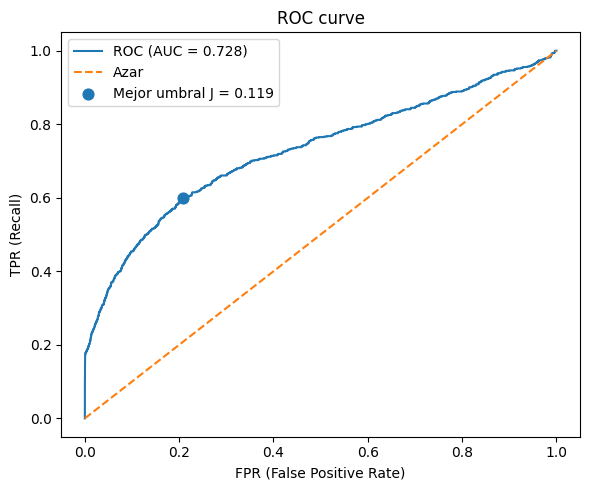

In [ ]:
# Calcula ROC y AUC
fpr, tpr, thr_roc = roc_curve(y_test, y_proba)  # guarda thresholds
auc_roc = roc_auc_score(y_test, y_proba)

# (A) Mejor umbral por Youden's J = TPR - FPR
youden = tpr - fpr
idx_j = np.argmax(youden)
thr_j = thr_roc[idx_j]
fpr_j, tpr_j = fpr[idx_j], tpr[idx_j]

# (B) (Opcional) Menor distancia a (0,1)
dist = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)
idx_d = np.argmin(dist)
thr_d = thr_roc[idx_d]
fpr_d, tpr_d = fpr[idx_d], tpr[idx_d]

# (C) (Opcional) Mejor F1 en curva PR (útil si la positiva es rara)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
idx_f1 = np.nanargmax(f1s[:-1])  # el último punto no tiene umbral
thr_f1 = thr_pr[idx_f1]

print(f"Umbral (Youden J): {thr_j:.4f}")
print(f"Umbral (Dist. a (0,1) mínima): {thr_d:.4f}")
print(f"Umbral (mejor F1 en PR): {thr_f1:.4f}")

# --- Plot ROC con el punto del mejor umbral (Youden J) ---
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_roc:.3f})")
plt.plot([0,1], [0,1], linestyle="--", label="Azar")

# Marca el mejor punto (Youden J)
plt.scatter([fpr_j], [tpr_j], s=60, marker='o',
            label=f"Mejor umbral J = {thr_j:.3f}")

# (Opcional) marca el de mínima distancia
# plt.scatter([fpr_d], [tpr_d], s=60, marker='s',
#             label=f"Min dist (thr={thr_d:.3f})")

plt.xlabel("FPR (False Positive Rate)")
plt.ylabel("TPR (Recall)")
plt.title("ROC curve")
plt.legend()
plt.tight_layout()
plt.show()

Mejor umbral (F1 máx): 0.2587
Precision=0.386  Recall=0.371  F1=0.378
Average Precision (AP): 0.392


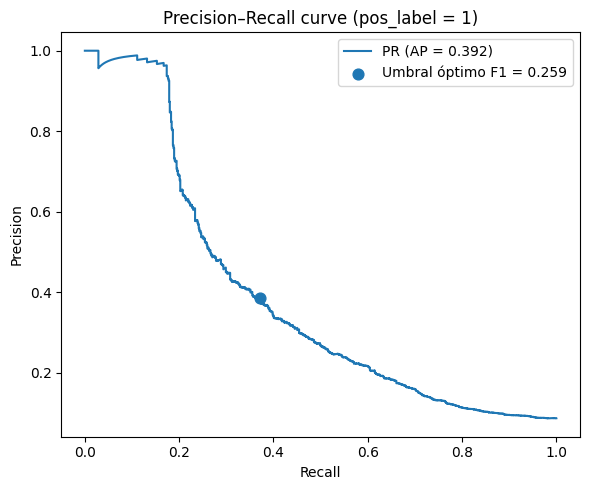

In [ ]:
pos_label = logreg.classes_[1]

# Curva PR (nota: len(thr_pr) = len(prec) - 1)
prec, rec, thr_pr = precision_recall_curve(y_test, y_proba)
ap = average_precision_score(y_test, y_proba)

# F1 en cada punto de la curva (el último punto no tiene umbral)
f1s = 2 * (prec * rec) / (prec + rec + 1e-12)
best_idx = np.nanargmax(f1s[:-1])      # evitar el último punto sin umbral
best_thr = thr_pr[best_idx]
best_prec = prec[best_idx]
best_rec = rec[best_idx]
best_f1 = f1s[best_idx]

print(f"Mejor umbral (F1 máx): {best_thr:.4f}")
print(f"Precision={best_prec:.3f}  Recall={best_rec:.3f}  F1={best_f1:.3f}")
print(f"Average Precision (AP): {ap:.3f}")

# Predicciones con el mejor umbral (si quieres usarlas)
y_pred_best = (y_proba >= best_thr).astype(int)

# --- Plot PR con el punto óptimo ---
plt.figure(figsize=(6,5))
plt.plot(rec, prec, label=f"PR (AP = {ap:.3f})")
plt.scatter([best_rec], [best_prec], s=60, marker='o',
            label=f"Umbral óptimo F1 = {best_thr:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall curve (pos_label = {pos_label})")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- 1) Usa el umbral óptimo que ya calculaste ---
thr_opt = best_thr   # p.ej., el que maximizó F1 en la curva PR

# --- 2) Probabilidades para la clase positiva ---
pos_label = logreg.classes_[1]
neg_label = logreg.classes_[0]
pos_idx = list(logreg.classes_).index(pos_label)

y_proba = logreg.predict_proba(X_test)[:, pos_idx]

# --- 3) Predicción con umbral custom ---
y_pred_thr = np.where(y_proba >= thr_opt, pos_label, neg_label)

# --- 4) Métricas con el nuevo umbral ---
print("Accuracy:", accuracy_score(y_test, y_pred_thr))
print("\nClassification report (umbral óptimo):\n",
      classification_report(y_test, y_pred_thr))

Accuracy: 0.8929390187987162

Classification report (umbral óptimo):
               precision    recall  f1-score   support

           0       0.94      0.94      0.94      7958
           1       0.39      0.37      0.38       766

    accuracy                           0.89      8724
   macro avg       0.66      0.66      0.66      8724
weighted avg       0.89      0.89      0.89      8724

